# 4. Clustering and 2-D structure

*Series:* [1. Data processing](01_data_processing.ipynb) · [2. Exploratory analysis](02_exploratory_analysis.ipynb) · [3. Classification](03_classification.ipynb) · **[4. Clustering](04_clustering.ipynb)** · [5. Explainability](05_explainability.ipynb)

---

Notebook 3 asked how much signal the features carry about a known label. This
notebook asks a different question: whether the cohort has structure *at all*,
and if it does, whether that structure corresponds to diabetes.

The labels are used only to score clusterings after the fact. Nothing here is
fitted with them.

Agreement is measured with adjusted Rand and adjusted mutual information, both
corrected for chance, so 0 means no better than a random partition of the same
shape. The alternative of relabelling clusters to whichever assignment looks
best and reporting accuracy starts at 50% for free on a binary outcome, and
flatters every result.

In [1]:
import warnings

import numpy as np
import pandas as pd
from sklearn.cluster import KMeans

from pima import cluster, plots
from pima.data import FEATURES, TARGET, load_processed

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)
plots.use_style()

df = load_processed()
y_all = df[TARGET].to_numpy()
matrix, imputed = cluster.prepare(df)      # median-imputed, standardised
print(f"clustering matrix: {matrix.shape}")

clustering matrix: (768, 8)


`prepare` does not add missing-value indicators. In supervised learning they
are extra signal. In a distance-based clustering they would add a binary axis
pulling every patient with an untaken insulin test toward the same corner of the
space, and the resulting clusters would describe who got tested instead of who
is ill.

## How many groups?

Four criteria, including the one everyone reaches for. Inertia falls
monotonically with k by definition, so its elbow is a judgement call about where
a smooth curve stops being steep. Silhouette and Davies-Bouldin have genuine
optima, and the mixture BIC penalises likelihood for parameters, which gives a
principled answer to how many components there are.

,k,inertia,silhouette,calinski_harabasz,davies_bouldin,bic
0,2,4975.0,0.1963,180.0,1.9202,15852.9
1,3,4335.7,0.1950,159.5,1.8327,11945.1
2,4,3912.4,0.1874,145.3,1.6296,11993.2
3,5,3677.1,0.1832,128.0,1.5803,9698.2
4,6,3475.6,0.1337,117.0,1.8629,9850.3
5,7,3304.6,0.1567,109.0,1.6988,10005.4
6,8,3142.9,0.1396,103.7,1.6587,10220.6
7,9,3003.4,0.1425,99.2,1.6065,10493.1
8,10,2888.7,0.1474,94.9,1.5598,10551.6


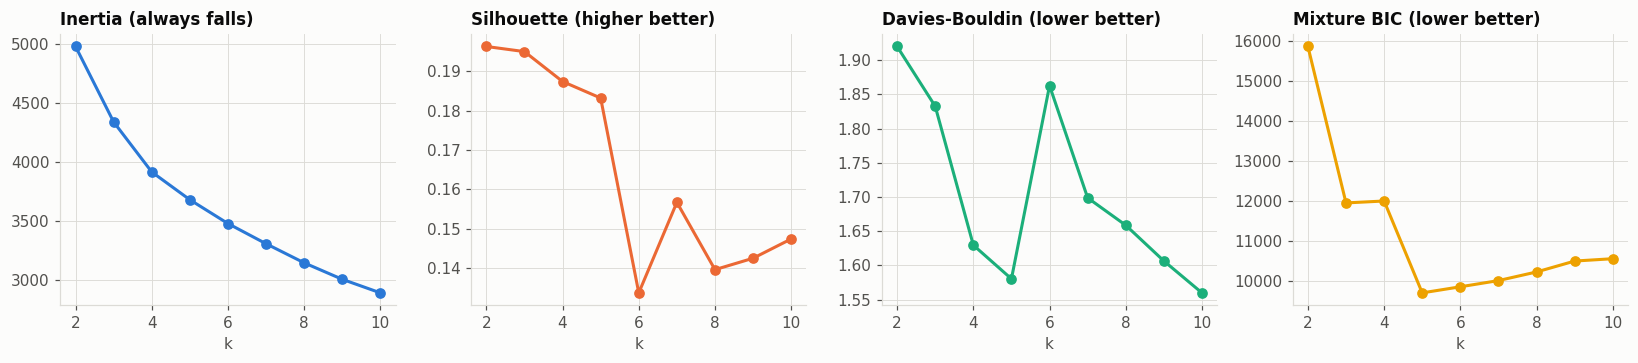

In [2]:
kmeans_k = cluster.k_selection(matrix)
gmm_k = cluster.gmm_selection(matrix)
plots.k_selection_curves(kmeans_k, gmm_k)
kmeans_k.merge(gmm_k[["k", "bic"]], on="k")

Silhouette peaks at k=2, at 0.196. As a rule of thumb, values below about 0.25
indicate no substantial structure, so even the best available k-means solution
is weakly separated.

The criteria also do not agree on k. Silhouette says 2, Davies-Bouldin says 10,
the mixture BIC bottoms out at 5, and inertia, falling monotonically by
definition, says nothing.

The disagreement is informative. When a dataset contains real, well-separated
groups, these measures tend to converge on the same k. When it is one continuous
cloud, each criterion finds a different arbitrary place to cut it.

## Four algorithms that assume different things

If a genuine two-group structure existed, methods this different should broadly
agree on it. k-means wants equal-sized spheres, the Gaussian mixture allows
elongated overlapping components with soft assignment, Ward agglomerative builds
a hierarchy with no centroid model, and DBSCAN looks for dense regions and is
free to call most of the cohort noise.

In [3]:
eps = cluster.suggest_dbscan_eps(matrix)
print(f"DBSCAN eps from the k-distance knee: {eps:.3f}")
cluster.compare_clusterers(matrix, y_all, k=2, eps=eps)

DBSCAN eps from the k-distance knee: 2.388


,algorithm,n_clusters,n_noise,largest_cluster_pct,silhouette,calinski_harabasz,davies_bouldin,adjusted_rand,adjusted_mutual_info
0,kmeans,2,0,54.3,0.1963,180.0,1.9202,0.1614,0.1204
1,gaussian_mixture,2,0,51.6,0.1587,140.0,2.1366,0.1135,0.1027
2,agglomerative_ward,2,0,75.9,0.1095,119.0,1.8335,-0.0165,0.0936
3,dbscan,1,27,96.5,NaN,NaN,NaN,0.0330,0.0222


They do not agree, and the best agreement with diabetes status is adjusted Rand
0.16, far closer to chance than to the label.

DBSCAN gives the most direct evidence. Given a principled `eps` it finds one
cluster and labels 27 patients as noise, so there are no dense regions separated
by sparse ones. Ward agglomerative manages -0.02, no better than randomly
partitioning the cohort into groups of the same sizes.

Taken together, the feature space is a single continuous cloud.

## The scaling trap

This is the most transferable result in the project, and the one an unwary
analysis gets backwards.

In [4]:
cluster.scaling_comparison(df, y_all)

,features,silhouette,calinski_harabasz,davies_bouldin,adjusted_rand,adjusted_mutual_info
0,raw,0.7250,967.9,0.5851,0.0295,0.0089
1,standardised,0.1963,180.0,1.9202,0.1614,0.1204


Read the silhouette column and raw features win overwhelmingly, 0.725 against
0.196. By that number alone, clustering on raw features produces well-separated
groups and standardising ruins them.

Read the agreement columns and it reverses. Raw features give an adjusted Rand
of 0.030, essentially zero, while standardised features give 0.161.

The raw clustering is a measurement artefact, and notebook 1 called it. It
noted that `Insulin` ranges over hundreds of units while
`DiabetesPedigreeFunction` spans less than three, so on unstandardised data
Euclidean distance is almost entirely insulin distance. k-means is splitting the
cohort on one variable, which produces a clean-looking boundary, and a high
silhouette, around nothing in particular.

Two things follow, and the second generalises:

- Distance-based methods require comparable scales. Without standardisation the
  widest-ranging variable silently becomes the only variable.
- Internal validation scores measure geometry. Silhouette asks whether a
  boundary is clean, which is a separate question from whether it separates
  anything. A clustering can score 0.725 and be worthless.

The two silhouette values should not be compared to one another at all, since
they are computed in different geometries.

## Is the clustering reproducible?

This is a separate question from whether the clustering is meaningful, and one
no internal score can answer. Two bootstrap resamples are drawn, each clustered
independently, and their labelings compared on the patients appearing in both.
Real structure survives resampling, while an arbitrary partition of a continuous
cloud moves every time the sample does.

In [5]:
km = KMeans(n_clusters=2, n_init=10, random_state=65)
cluster.bootstrap_stability(matrix, km, n_resamples=50)

{'mean_ari': 0.8333, 'sd_ari': 0.075, 'min_ari': 0.6568}

Mean adjusted Rand is 0.83, which is highly reproducible. Resample the cohort
and k-means draws very nearly the same boundary.

Put beside the previous result, this is more interesting than a failed
clustering. The split is consistent and repeatable, and it agrees with the
outcome at only 0.16. Whatever that boundary separates is real, and it is
something other than the label.

## What is in the clusters

This step decides whether a clustering is worth anything, since a cluster is
only interesting if you can say what kind of patient is in it. Values are
reported in clinical units, because "mean BMI 35.3" is readable where "0.83
standard deviations" is not.

In [6]:
labels = km.fit_predict(matrix)
cluster.cluster_profile(imputed, labels, y_all)

,cluster,n,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,diabetes_rate
0,0,417,2.2,108.0,67.0,26.0,117.3,30.0,0.4,26.6,0.175
1,1,351,5.8,137.9,78.8,32.7,168.5,35.3,0.5,41.1,0.556


The clusters are easy to interpret, and what separates them is age and
metabolic load.

Cluster 0 (417 patients) is younger: mean age 27, 2.2 pregnancies, glucose 108,
BMI 30. Cluster 1 (351) is older at 41, with 5.8 pregnancies, glucose 138, BMI
35, and higher insulin and blood pressure. Every feature moves the same
direction at once, which is why the split is so stable. It follows a single
underlying gradient.

Diabetes prevalence follows that gradient loosely, at 17.5% in cluster 0
against 55.6% in cluster 1. Cluster 1 is a genuine high-risk group, and 44% of
its members are still not diabetic.

What the unsupervised methods recovered is a real and clinically sensible risk
gradient, which is a different thing from a diagnosis. The clustering found
structure, and that structure turned out to be something other than the label.

## How much the 2-D projections can show

Before plotting, it helps to know how much of the data a 2-D picture can
represent.

,component,explained_variance_ratio,cumulative
0,PC1,0.2854,0.2854
1,PC2,0.1869,0.4723
2,PC3,0.1427,0.6150
3,PC4,0.1146,0.7296
4,PC5,0.0961,0.8257
5,PC6,0.0679,0.8936
6,PC7,0.0586,0.9521
7,PC8,0.0479,1.0000


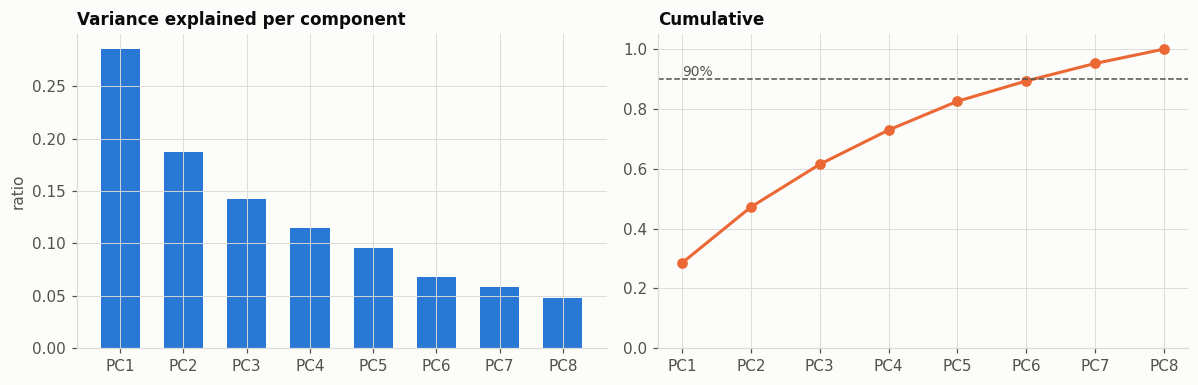

In [7]:
variance, loadings = cluster.pca_components(matrix)
plots.pca_scree(variance)
variance

The first two components carry only about 47% of the variance, so more than
half of the structure is invisible in any 2-D scatter below. That makes "the
groups overlap in this picture" weaker evidence than it looks. The agreement
metrics above, computed in the full 8-dimensional space, are the primary
evidence, and these plots are illustration.

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
PC1,0.301,0.424,0.377,0.397,0.307,0.402,0.157,0.386
PC2,0.558,-0.082,0.172,-0.309,-0.236,-0.398,-0.273,0.518
PC3,-0.025,0.442,-0.305,-0.398,0.574,-0.381,0.270,0.072


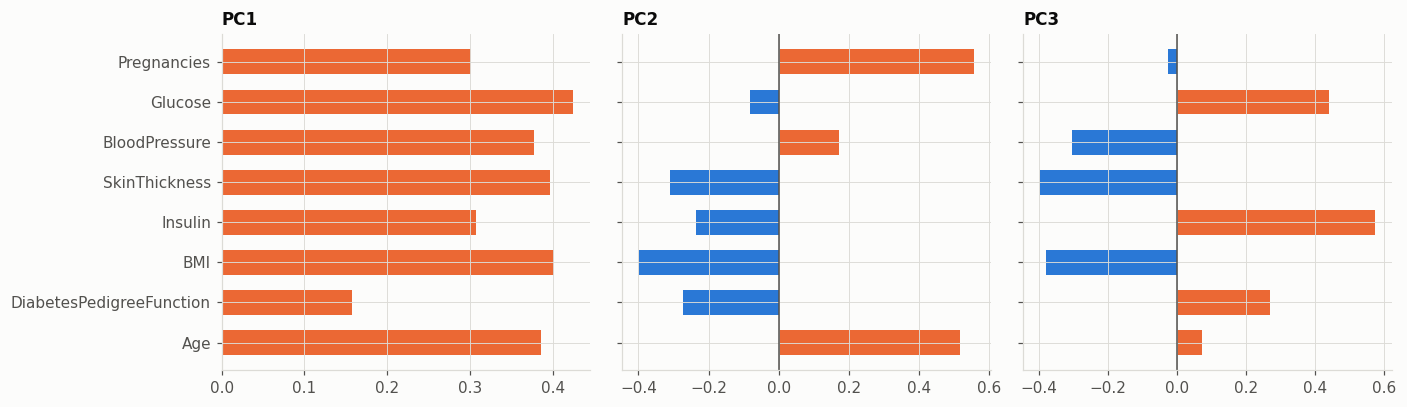

In [8]:
plots.component_loadings(loadings)
loadings.iloc[:3]

PC1 loads positively on every feature at once, making it an overall
metabolic-magnitude axis rather than a contrast between features. That is the
signature of a dataset whose features are all mild proxies for one another, and
it is the same gradient the cluster profile described. PC2 separates
`Pregnancies` and `Age` (both around +0.5) from `BMI`, `SkinThickness` and
`Insulin` (all negative): an age axis set against a body-composition axis.

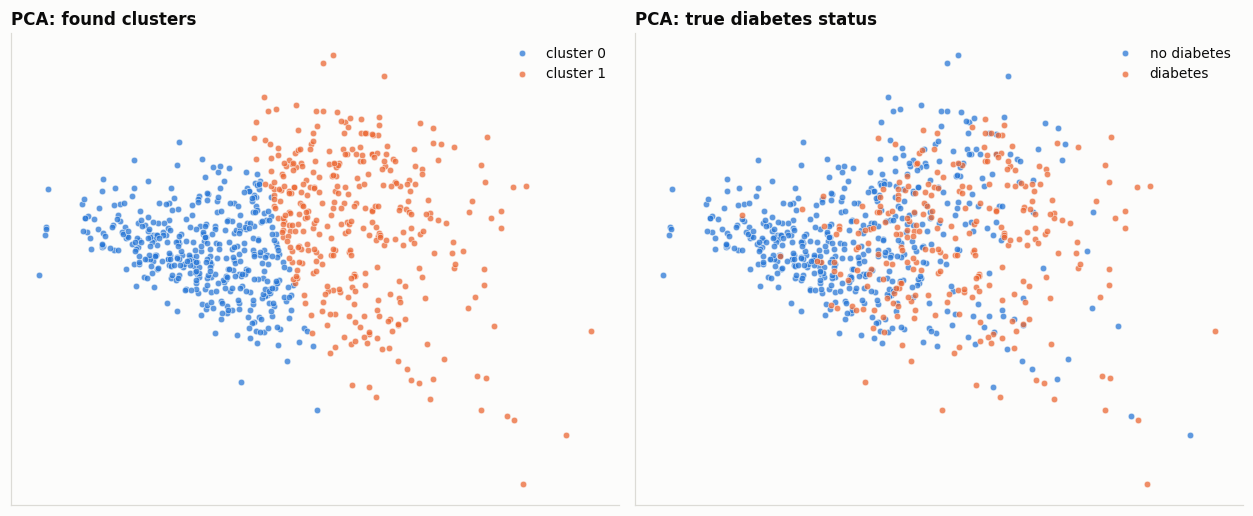

In [9]:
embeddings = cluster.projections(matrix)
plots.projection(embeddings["pca"], labels, y_all, "PCA");

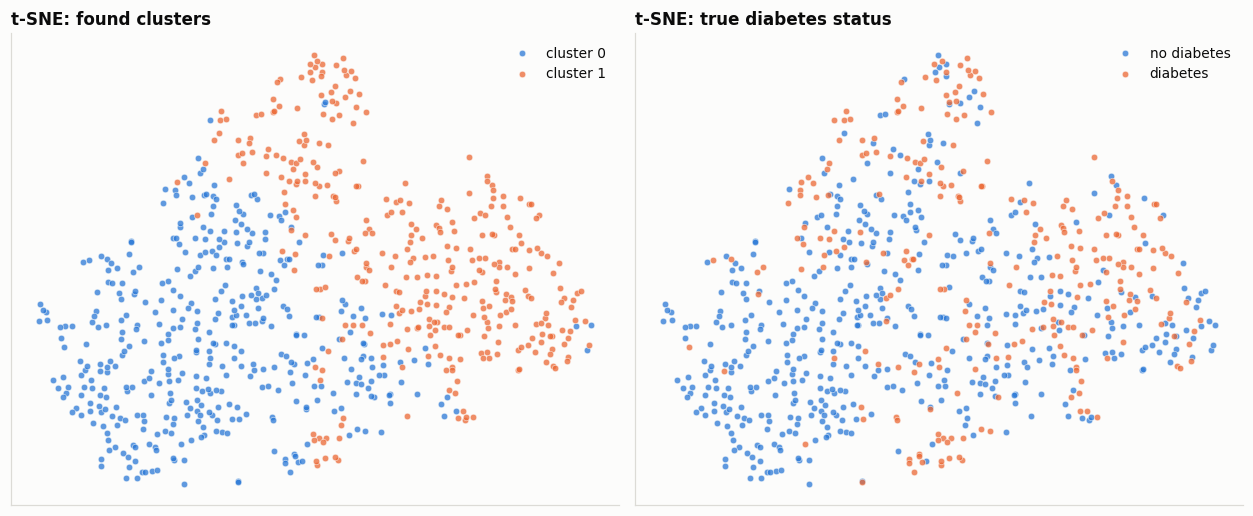

In [10]:
plots.projection(embeddings["tsne"], labels, y_all, "t-SNE");

The left panels show a clean split, because that is where k-means drew its
line, along PC1, the metabolic-magnitude axis. The right panels show the true
labels smeared across the same space with no comparable boundary. If the
clusters corresponded to diabetes, the two panels would look alike.

A caveat on the second figure: t-SNE distances are not distances. It preserves
local neighbourhoods and distorts global geometry, so the size of its blobs and
the gaps between them are artefacts of the perplexity setting. It is included
as the standard diagnostic, and should be read only for whether the label
colours mix, which they do. The PCA panel is the one where overlap is a
statement about the feature space itself.

---
## Summary

- The cohort does not divide into diabetic and non-diabetic groups. The best
  agreement across four algorithms is adjusted Rand 0.16. DBSCAN finds one
  dense region and Ward agglomerative does no better than chance.
- The k=2 split is highly reproducible (bootstrap ARI 0.83) and clinically
  legible: a younger, lower-BMI group against an older, higher-glucose one,
  17.5% against 55.6% diabetic.
- What the unsupervised methods recovered is a metabolic risk gradient.
- Raw-feature clustering scores 3.7x better on silhouette while recovering
  essentially none of the outcome, which shows internal scores measuring
  geometry alone.
- PC1 and PC2 hold only about 47% of the variance, so the 2-D plots are
  illustration and the full-space metrics are the evidence.

Next: [5. Explainability](05_explainability.ipynb).